In [1]:
import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

PROJECT_ROOT = Path('.').resolve() if (Path('.').resolve() / 'config').exists() else Path('.').resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.special import softmax

from config.settings import (
    PROCESSED_DATASET_DIR,
    TARGET_COLUMN,
    TARGET_CLASSES,
    TABLES_DIR,
    FIGURES_DIR,
)
from src.features.feature_engineering import add_engineered_features
from src.models.model_persistence import load_model_pipeline, load_label_encoder
from src.evaluation.classification_metrics import compute_comprehensive_metrics
from src.evaluation.confusion_analysis import compute_confusion_matrices, find_top_confused_pairs
from src.evaluation.prediction_analysis import extract_misclassified_samples

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print('Phase 6 evaluation environment initialized.')

Phase 6 evaluation environment initialized.


In [2]:
pipeline = load_model_pipeline('best_model')
encoder = load_label_encoder('target_label_encoder')
class_names = list(encoder.classes_)

import json
with open(PROCESSED_DATASET_DIR / 'split_metadata.json') as f:
    meta = json.load(f)

cleaned_df = pd.read_csv(PROCESSED_DATASET_DIR / 'cleaned_dry_beans.csv')
df_all = add_engineered_features(cleaned_df)
test_df = df_all.iloc[meta['test_indices']].copy()

feat_cols = [c for c in test_df.columns if c != TARGET_COLUMN]
X_test = test_df[feat_cols]
y_test = encoder.transform(test_df[TARGET_COLUMN])

print(f'Model Pipeline Loaded: {[s[0] for s in pipeline.steps]}')
print(f'Held-Out Test Observations: {len(test_df):,} ({len(test_df)/len(df_all)*100:.2f}%)')
print(f'Feature Count: {len(feat_cols)}')
print(f'Target Varieties ({len(class_names)}): {class_names}')

Model Pipeline Loaded: ['scaler', 'classifier']
Held-Out Test Observations: 2,032 (15.00%)
Feature Count: 22
Target Varieties (7): ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']


In [3]:
import time
t0 = time.perf_counter()
y_pred = pipeline.predict(X_test)
inf_time = time.perf_counter() - t0
per_sample_ms = (inf_time / len(X_test)) * 1000

if hasattr(pipeline, 'predict_proba'):
    y_proba = pipeline.predict_proba(X_test)
elif hasattr(pipeline, 'decision_function'):
    y_proba = softmax(pipeline.decision_function(X_test), axis=1)
else:
    y_proba = None

print(f'Total Inference Time: {inf_time:.4f}s')
print(f'Latency per Sample: {per_sample_ms:.4f} ms')

Total Inference Time: 0.4401s
Latency per Sample: 0.2166 ms


In [4]:
metrics = compute_comprehensive_metrics(y_test, y_pred, y_proba, class_names=class_names)
summary_table = pd.DataFrame([{
    'Metric': 'Overall Accuracy',
    'Value': f"{metrics['accuracy']*100:.2f}%",
}, {
    'Metric': 'Balanced Accuracy',
    'Value': f"{metrics['balanced_accuracy']*100:.2f}%",
}, {
    'Metric': 'Macro Precision',
    'Value': f"{metrics['macro_precision']:.4f}",
}, {
    'Metric': 'Macro Recall',
    'Value': f"{metrics['macro_recall']:.4f}",
}, {
    'Metric': 'Macro F1-Score',
    'Value': f"{metrics['macro_f1']:.4f}",
}, {
    'Metric': 'Weighted F1-Score',
    'Value': f"{metrics['weighted_f1']:.4f}",
}, {
    'Metric': 'Matthews Correlation Coefficient (MCC)',
    'Value': f"{metrics['matthews_corrcoef']:.4f}",
}, {
    'Metric': "Cohen's Kappa",
    'Value': f"{metrics['cohens_kappa']:.4f}",
}, {
    'Metric': 'Multiclass ROC-AUC (OvR)',
    'Value': f"{metrics['roc_auc_ovr']:.4f}",
}])
display(summary_table)

,Metric,Value
0,Overall Accuracy,92.22%
1,Balanced Accuracy,93.26%
2,Macro Precision,0.9346
3,Macro Recall,0.9326
4,Macro F1-Score,0.9334
5,Weighted F1-Score,0.9224
6,Matthews Correlation Coefficient (MCC),0.9060
7,Cohen's Kappa,0.9059
8,Multiclass ROC-AUC (OvR),0.9901


,Cultivar,Precision,Recall,F1-Score,Support
0,BARBUNYA,0.9368,0.8990,0.9175,198
1,BOMBAY,1.0000,1.0000,1.0000,78
2,CALI,0.9173,0.9510,0.9339,245
3,DERMASON,0.9278,0.9173,0.9225,532
4,HOROZ,0.9596,0.9355,0.9474,279
5,SEKER,0.9472,0.9441,0.9456,304
6,SIRA,0.8533,0.8813,0.8671,396


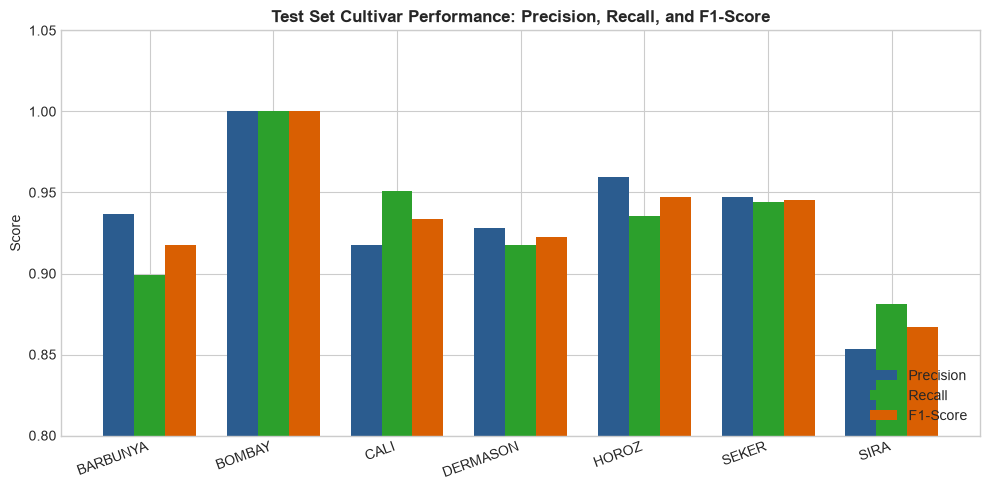

In [5]:
per_class_df = pd.DataFrame(metrics['per_class_metrics'])
display(per_class_df)

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(per_class_df))
width = 0.25
ax.bar(x - width, per_class_df['Precision'], width, label='Precision', color='#2b5c8f')
ax.bar(x, per_class_df['Recall'], width, label='Recall', color='#2ca02c')
ax.bar(x + width, per_class_df['F1-Score'], width, label='F1-Score', color='#d95f02')
ax.set_xticks(x)
ax.set_xticklabels(per_class_df['Cultivar'], rotation=20, ha='right')
ax.set_ylim([0.80, 1.05])
ax.set_ylabel('Score')
ax.set_title('Test Set Cultivar Performance: Precision, Recall, and F1-Score', fontweight='bold')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

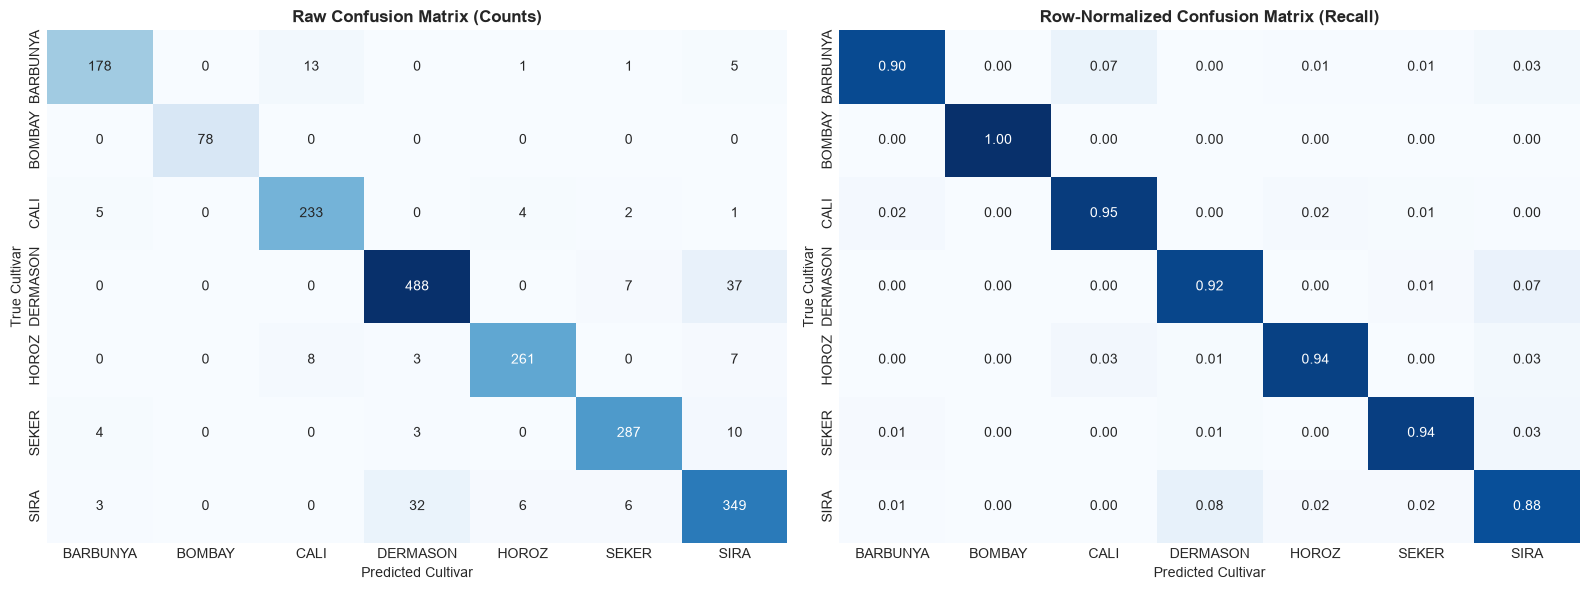

In [6]:
cm_dict = compute_confusion_matrices(y_test, y_pred, class_names=class_names)
cm_raw = cm_dict['raw_confusion_matrix']
cm_norm = cm_dict['normalized_confusion_matrix']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(cm_raw, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax1)
ax1.set_title('Raw Confusion Matrix (Counts)', fontweight='bold')
ax1.set_xlabel('Predicted Cultivar')
ax1.set_ylabel('True Cultivar')

sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', cbar=False, ax=ax2)
ax2.set_title('Row-Normalized Confusion Matrix (Recall)', fontweight='bold')
ax2.set_xlabel('Predicted Cultivar')
ax2.set_ylabel('True Cultivar')
plt.tight_layout()
plt.show()

In [7]:
top_confused = find_top_confused_pairs(y_test, y_pred, class_names=class_names)
print('Top Confused Cultivar Pairs:')
display(top_confused)

mis_samples = extract_misclassified_samples(X_test, y_test, y_pred, class_names, y_proba)
print(f'Total Misclassifications: {len(mis_samples)} / {len(X_test)} ({len(mis_samples)/len(X_test)*100:.2f}%)')
display(mis_samples.head(10))

Top Confused Cultivar Pairs:


,True Cultivar,Predicted Cultivar,Misclassified Count,Misclassified % of Class
0,DERMASON,SIRA,37,6.95
1,SIRA,DERMASON,32,8.08
2,BARBUNYA,CALI,13,6.57
3,SEKER,SIRA,10,3.29
4,HOROZ,CALI,8,2.87


Total Misclassifications: 158 / 2032 (7.78%)


,Sample_Index,True_Class,Predicted_Class,Prediction_Confidence,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,roundness,Compactness
0,4462,CALI,HOROZ,0.7046,71810.0,1055.735,385.0462,246.3794,1.5628,0.8096,0.7853
1,2021,SEKER,BARBUNYA,0.6941,56693.0,933.372,304.4774,237.5331,1.2818,0.8178,0.8824
2,9239,SIRA,BARBUNYA,0.6919,47184.0,856.996,302.8667,199.1194,1.5210,0.8073,0.8093
3,13385,DERMASON,SIRA,0.6915,40234.0,760.325,277.2966,186.0181,1.4907,0.8746,0.8162
4,9763,SIRA,BARBUNYA,0.6842,50976.0,932.171,327.6430,199.2144,1.6447,0.7372,0.7776
5,13202,DERMASON,SIRA,0.6836,38760.0,753.761,276.7611,178.6878,1.5489,0.8573,0.8027
6,4653,CALI,BARBUNYA,0.6823,74400.0,1060.024,393.9101,241.1259,1.6336,0.8321,0.7813
7,3872,CALI,SEKER,0.6797,45666.0,789.770,274.8634,211.8851,1.2972,0.9200,0.8773
8,1844,SEKER,SIRA,0.6790,46427.0,811.657,293.9180,202.2462,1.4533,0.8856,0.8272
9,2883,BARBUNYA,CALI,0.6777,73097.0,1028.668,376.5885,249.0109,1.5123,0.8681,0.8101
